# Primeiro contato com Machine Learning em um fluxo corporativo

Este notebook simula um experimento inicial de uma equipe de dados/ML usando duas bases reais disponibilizadas pelo scikit-learn. O objetivo é entender onde NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn e PyTorch aparecem no fluxo.

Fluxo: ingestão → qualidade → exploração → treino/teste → baseline → pipeline → métricas → comparação com PyTorch.

## 1. Preparação e reprodutibilidade

Em um ambiente corporativo, registramos versões e sementes aleatórias para facilitar a reprodução do experimento.

In [1]:
from pathlib import Path
import platform
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Saídas:", OUTPUT_DIR)

Python: 3.13.15
NumPy: 2.5.2
Pandas: 3.0.6
Scikit-learn: 1.9.1
PyTorch: 2.14.1+cu130
Saídas: C:\Users\luizs\Documents\Projetos\MLOPS\01-ml-classificacao-fundamentos\notebooks\notebooks\outputs


## 2. Duas bases reais

- `Breast Cancer Wisconsin`: classificação binária;
- `Diabetes`: regressão com alvo contínuo.

Cada problema exige alvo, métrica e modelo adequados.

In [2]:
from sklearn.datasets import load_breast_cancer, load_diabetes

cancer = load_breast_cancer(as_frame=True)
cancer_df = cancer.frame.copy()
diabetes = load_diabetes(as_frame=True)
diabetes_df = diabetes.frame.copy()

print("Classificação:", cancer_df.shape)
display(cancer_df.head(3))
print("Regressão:", diabetes_df.shape)
display(diabetes_df.head(3))

Classificação: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


Regressão: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0


## 3. Pandas: qualidade dos dados

Antes de treinar, verificamos tipos, nulos, cardinalidade, distribuição do alvo e estatísticas básicas.

In [3]:
def quality_report(data: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "missing": data.isna().sum(),
        "missing_pct": data.isna().mean().mul(100).round(2),
        "unique": data.nunique(),
    }).sort_values("missing", ascending=False)

display(quality_report(cancer_df).head(10))
print("Distribuição das classes:")
display(cancer_df["target"].value_counts().rename_axis("class").to_frame("count"))
print("Estatísticas do alvo de regressão:")
display(diabetes_df["target"].describe().to_frame("target"))

,dtype,missing,missing_pct,unique
mean radius,float64,0,0.0,456
mean texture,float64,0,0.0,479
mean perimeter,float64,0,0.0,522
mean area,float64,0,0.0,539
mean smoothness,float64,0,0.0,474
mean compactness,float64,0,0.0,537
mean concavity,float64,0,0.0,537
mean concave points,float64,0,0.0,542
mean symmetry,float64,0,0.0,432
mean fractal dimension,float64,0,0.0,499


Distribuição das classes:


,count
class,
1,357
0,212


Estatísticas do alvo de regressão:


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


## 4. NumPy, Matplotlib e Seaborn: exploração

Pandas organiza as tabelas, NumPy fornece operações numéricas e Matplotlib/Seaborn ajudam a avaliar distribuições, separação e correlações. Gráficos não provam causalidade.

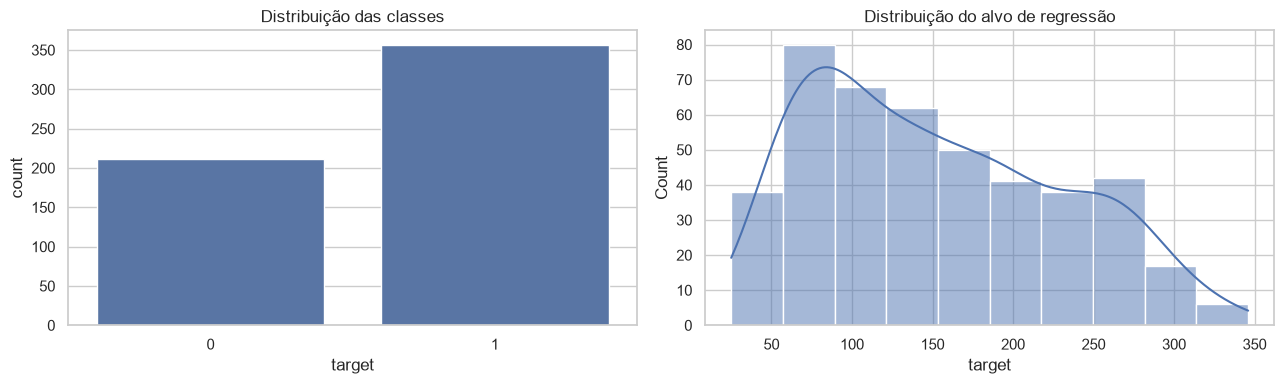

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=cancer_df, x="target", ax=axes[0])
axes[0].set_title("Distribuição das classes")
sns.histplot(data=diabetes_df, x="target", kde=True, ax=axes[1])
axes[1].set_title("Distribuição do alvo de regressão")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "distribuicoes.png", dpi=150)
plt.show()

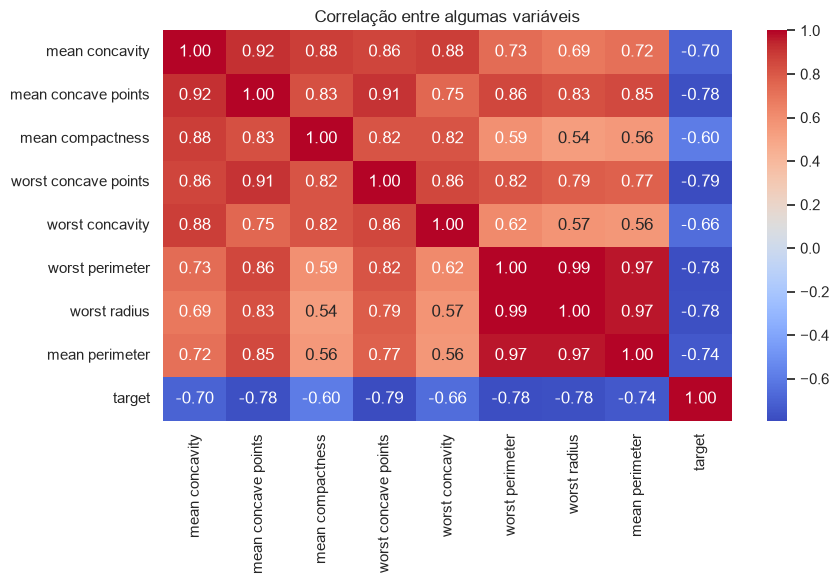

In [5]:
correlations = cancer_df.drop(columns="target").corr(numeric_only=True)
top_features = correlations.abs().mean().nlargest(8).index
plt.figure(figsize=(9, 6))
sns.heatmap(cancer_df[list(top_features) + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlação entre algumas variáveis")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "heatmap-correlacao.png", dpi=150)
plt.show()

## 5. Scikit-learn: baseline, pipeline e avaliação

O baseline fornece um ponto de comparação. A `Pipeline` encapsula o pré-processamento e o modelo, fazendo o `StandardScaler` aprender apenas com o conjunto de treino.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_cls = cancer_df.drop(columns="target")
y_cls = cancer_df["target"]
X_train, X_test, y_train, y_test = train_test_split(X_cls, y_cls, test_size=0.2, random_state=SEED, stratify=y_cls)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
])
logistic_pipeline.fit(X_train, y_train)
predictions = logistic_pipeline.predict(X_test)

print("Acurácia do baseline:", round(accuracy_score(y_test, baseline_pred), 3))
print("Acurácia da regressão logística:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions, target_names=cancer.target_names))

Acurácia do baseline: 0.632
Acurácia da regressão logística: 0.982
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



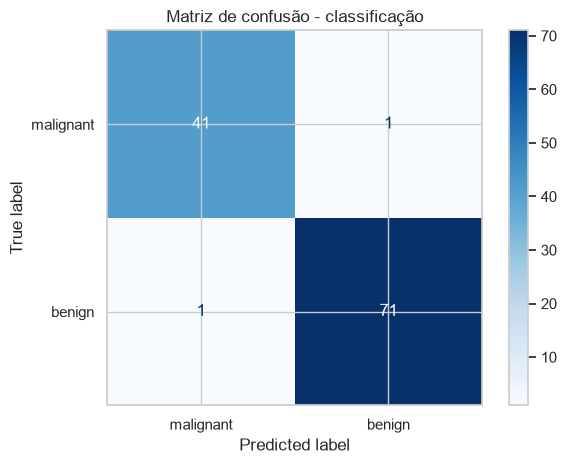

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=cancer.target_names, cmap="Blues")
plt.title("Matriz de confusão - classificação")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "matriz-confusao.png", dpi=150)
plt.show()

In [8]:
X_reg = diabetes_df.drop(columns="target")
y_reg = diabetes_df["target"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=SEED)

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0)),
])
ridge_pipeline.fit(X_train_reg, y_train_reg)
reg_predictions = ridge_pipeline.predict(X_test_reg)

rmse = np.sqrt(mean_squared_error(y_test_reg, reg_predictions))
print("MAE:", round(mean_absolute_error(y_test_reg, reg_predictions), 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2_score(y_test_reg, reg_predictions), 3))

MAE: 42.812
RMSE: 53.777
R²: 0.454


### O que mudou depois do scaling?

O scaler aprende média e desvio padrão somente com X_train_reg. A célula abaixo compara as primeiras linhas antes e depois da transformação.

In [9]:
scaler_reg = StandardScaler()
scaler_reg.fit(X_train_reg)
X_train_reg_scaled = pd.DataFrame(
    scaler_reg.transform(X_train_reg),
    columns=X_train_reg.columns,
    index=X_train_reg.index,
)

print("Antes do scaling:")
display(X_train_reg.head(3).round(3))
print("Depois do StandardScaler:")
display(X_train_reg_scaled.head(3).round(3))

comparison = pd.DataFrame({
    "media_antes": X_train_reg.mean(),
    "desvio_antes": X_train_reg.std(),
    "media_depois": X_train_reg_scaled.mean(),
    "desvio_depois": X_train_reg_scaled.std(),
})
display(comparison.round(3))

Antes do scaling:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
17,0.071,0.051,0.012,0.056,0.034,0.049,-0.040,0.034,0.027,-0.001
66,-0.009,0.051,-0.018,-0.033,-0.021,0.012,-0.073,0.071,0.000,0.020
137,0.005,-0.045,0.050,0.098,-0.015,-0.016,-0.007,-0.003,0.017,-0.014


Depois do StandardScaler:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
17,1.498,1.061,0.220,1.139,0.728,1.056,-0.824,0.711,0.547,-0.061
66,-0.229,1.061,-0.419,-0.711,-0.425,0.272,-1.530,1.484,-0.020,0.367
137,0.085,-0.942,1.019,1.992,-0.310,-0.327,-0.119,-0.062,0.331,-0.319


,media_antes,desvio_antes,media_depois,desvio_depois
age,0.001,0.046,-0.0,1.001
sex,0.000,0.048,-0.0,1.001
bmi,0.002,0.047,-0.0,1.001
bp,0.001,0.048,0.0,1.001
s1,-0.001,0.048,-0.0,1.001
s2,-0.001,0.048,-0.0,1.001
s3,-0.001,0.047,0.0,1.001
s4,0.000,0.048,-0.0,1.001
s5,0.001,0.048,-0.0,1.001
s6,0.002,0.048,0.0,1.001


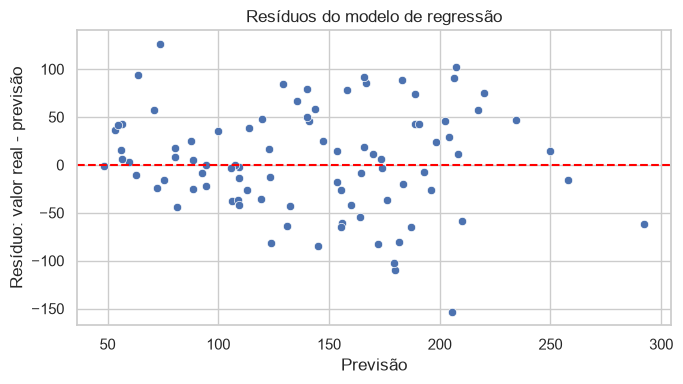

In [10]:
residuals = y_test_reg.to_numpy() - reg_predictions
plt.figure(figsize=(7, 4))
sns.scatterplot(x=reg_predictions, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Previsão")
plt.ylabel("Resíduo: valor real - previsão")
plt.title("Resíduos do modelo de regressão")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "residuos-regressao.png", dpi=150)
plt.show()

## 6. PyTorch: loop explícito de treinamento

Agora treinamos uma rede neural pequena no problema de classificação. O objetivo é entender o fluxo `tensor → modelo → loss → gradiente → atualização`, não superar automaticamente o modelo clássico.

In [11]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch_scaler = StandardScaler()
X_train_scaled = torch_scaler.fit_transform(X_train)
X_test_scaled = torch_scaler.transform(X_test)
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)
torch_model = nn.Sequential(nn.Linear(X_train_t.shape[1], 32), nn.ReLU(), nn.Linear(32, 2))
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.001)

loss_history = []
for epoch in range(80):
    torch_model.train()
    epoch_loss = 0.0
    for batch_X, batch_y in train_loader:
        logits = torch_model(batch_X)
        loss = loss_function(logits, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch_X)
    loss_history.append(epoch_loss / len(train_loader.dataset))

torch_model.eval()
with torch.no_grad():
    torch_predictions = torch_model(X_test_t).argmax(dim=1).numpy()

print("Acurácia PyTorch:", round(accuracy_score(y_test, torch_predictions), 3))

Acurácia PyTorch: 0.965


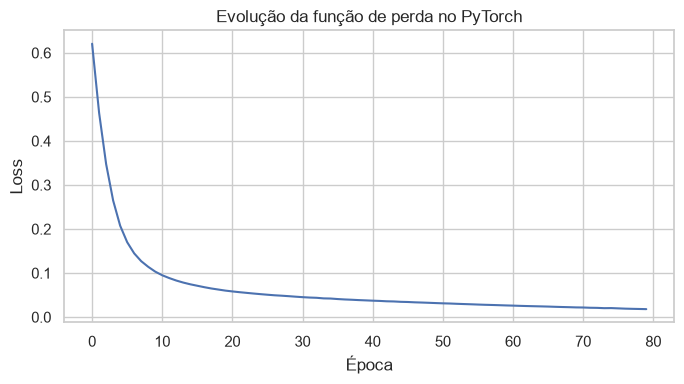

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da função de perda no PyTorch")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss-pytorch.png", dpi=150)
plt.show()

## 7. CPU versus CUDA: quando a GPU ajuda

CUDA permite executar operações de tensores em uma GPU NVIDIA. O ganho aparece principalmente em operações paralelas e maiores; para modelos pequenos, a transferência de dados e o custo de inicialização podem eliminar a vantagem.

A célula abaixo mede um pequeno treinamento sintético em CPU e, se o PyTorch CUDA estiver instalado e a GPU for reconhecida, também em CUDA.

In [13]:
import time

def benchmark_training(device_name: str, epochs: int = 8) -> float:
    device = torch.device(device_name)
    torch.manual_seed(SEED)
    X_bench = torch.randn(12000, 64, device=device)
    y_bench = torch.randint(0, 2, (12000,), device=device)
    model = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 2)).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()
    start = time.perf_counter()
    for _ in range(epochs):
        logits = model(X_bench)
        loss = loss_function(logits, y_bench)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter() - start

cpu_seconds = benchmark_training("cpu")
print(f"CPU: {cpu_seconds:.2f}s")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    cuda_seconds = benchmark_training("cuda")
    print(f"CUDA: {cuda_seconds:.2f}s")
    print(f"Aceleração aproximada: {cpu_seconds / cuda_seconds:.2f}x")
else:
    print("CUDA não disponível neste ambiente. O benchmark GPU será executado quando o PyTorch com CUDA estiver instalado.")

CPU: 0.03s
GPU: NVIDIA GeForce RTX 5070


CUDA: 14.79s
Aceleração aproximada: 0.00x


## 7. Leitura corporativa

Antes de considerar um modelo pronto para uso, ainda precisaríamos verificar se os dados representam o processo real, se as features estarão disponíveis no momento da decisão, se há leakage, qual erro é mais caro, se o desempenho é estável ao longo do tempo e como o modelo será monitorado após o deploy.

Este notebook é um primeiro contato com o fluxo técnico; não substitui validação de negócio, governança, testes ou monitoramento.